# Lecture 11 Quiz: Logistic Regression & Classification

### **The Scenario**

You are working for a healthcare tech startup. You have a dataset of patients who were tested for a specific condition. Your goal is to move beyond the "blob separation" of GMMs and build a predictive model that estimates the probability of a patient having the condition based on their symptoms. You will implement Logistic Regression and explore the concepts of Generalization and Validation.

### Part 1: Conceptual Stress-Tests

**Question 1: The "S" Curve**

In Linear Regression, we output the raw score $y = \mathbf{w}^T\mathbf{x}$. In Logistic Regression, we pass this output through the **Sigmoid (Logistic) function**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$



[Image of Sigmoid function curve]


**Why do we do this?**

A) To make the loss function linear.

B) To squash the output between 0 and 1, allowing it to be interpreted as a probability.

C) To ensure the gradient is always constant.

D) To penalize outliers more heavily than Mean Squared Error does.

#### Answer:
- B) To squash the output between 0 and 1, allowing it to be interpreted as a probability.

 This gets the range of output in 0,1 range this helps to interpret as probability. also a good quality of this function is it is very much differentiable, whidh also helps

**Question 2: Generalization & The "Ugly Duckling"**

You train a model on your training set ($D_{Tr}$) and achieve 99% accuracy. However, when you deploy it on the test set ($D_{Te}$), the accuracy drops to 65%. This is a classic problem in machine learning.

**Which of the following is the most likely cause and the most common remedy?**

A) **Underfitting**; increase the model complexity to capture more noise.

B) **High Bias**; collect more training data to simplify the model.

C) **Overfitting**; apply regularization (like $L_1$ or $L_2$ norms) to penalize high weights.

D) **Lucky Split**; no action needed, the test set is simply mathematically distinct.



#### Answer:
- C) **Overfitting**; apply regularization (like $L_1$ or $L_2$ norms) to penalize high weights.

 You generally apply regularization, but also you can collect more diverese sets which helps model to adjust it's weights, k-fold cross validation kind of approach also helps sometimes as sometime the val set may not be that representative.

### **Part 2: The Arithmetic of Belief**

**Question 3: The Rare Disease Paradox**

**Scenario:**
A disease is prevalent in only **1%** of the population ($P(D) = 0.01$).
A medical test is **90% accurate** in both directions:
* **True Positive Rate:** $P(+\text{ | } D) = 0.90$
* **True Negative Rate:** $P(-\text{ | } \text{no } D) = 0.90$

**The Test:**
A patient takes the test and it comes back **POSITIVE**.

**Task:**
Calculate the probability that the patient actually has the disease.
$$P(D \text{ | } +) = \frac{P(+ \text{ | } D)P(D)}{P(+)}$$

*Show your calculation steps below using Bayes' Theorem.*

#### Your Solution:
...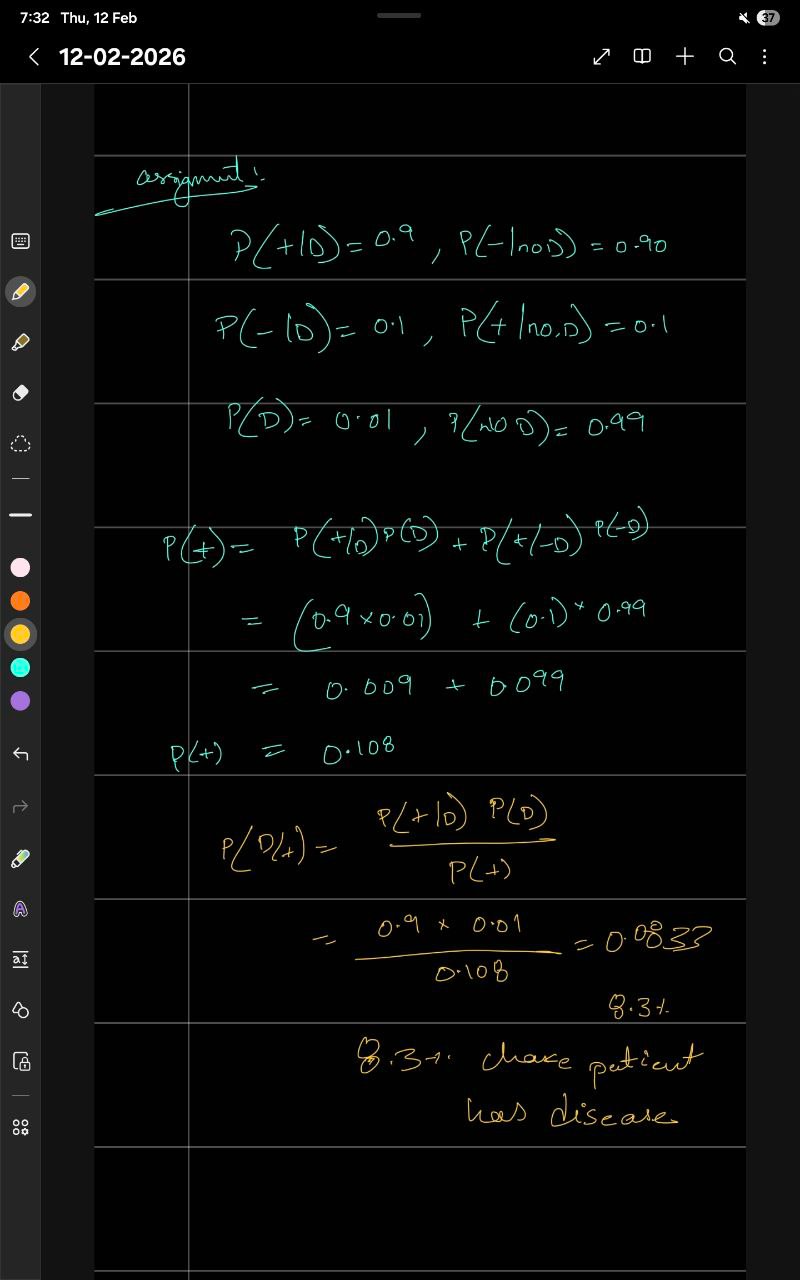

In [12]:
0.9*0.01/0.108

0.08333333333333334

### **Part 3: Coding Challenge — Writing the Logistic Suite**

In this section, you will implement the core optimization logic for two types of classification models.

#### **Task 1: Binary Logistic Regression (Gradient Descent)**
Separate the data into two classes (e.g., "Pass" vs "Fail").

**Formulas for Reference:**

**1. Prediction:** $\hat{y}_i = \sigma(\mathbf{w}^T\mathbf{x}_i)$ \
**2. Gradient Update:** $\mathbf{w} = \mathbf{w} - \eta \frac{1}{N} \mathbf{X}^T (\mathbf{\hat{y}} - \mathbf{y})$

In [5]:
import numpy as np

# --- 1. Setup Synthetic Data ---
np.random.seed(0)
# Features: [Hours Studied, Sleep Quality]
X = np.array([[2, 3], [1, 1], [5, 2], [3, 2], [7, 3], [8, 4]])
# Labels: [Fail, Fail, Pass, Fail, Pass, Pass]
y = np.array([0, 0, 1, 0, 1, 1])

# Add bias term (column of ones)
X_b = np.c_[np.ones((X.shape[0], 1)), X]

# Initialize weights
w = np.zeros(X_b.shape[1])
learning_rate = 0.1
epochs = 1000

def sigmoid(z):

    # -----------------------------------------------------
    # TODO: Implement the sigmoid function


    return 1/(1+np.exp(-z))
    # -----------------------------------------------------

def train_logistic_regression(X, y, w, lr, epochs):
    N = len(y)
    for epoch in range(epochs):
        # -----------------------------------------------------
        # TODO: Implement Gradient Descent
        # 1. Calculate z = Xw
        # 2. Calculate predictions (y_hat) using sigmoid(z)
        # 3. Calculate the gradient: (1/N) * X.T dot (y_hat - y)
        # 4. Update weights: w = w - lr * gradient
        # -----------------------------------------------------
        print(w)
        z= X.dot(w)
        y_hat = sigmoid(z)
        gradient = (1/N) * X.T.dot(y_hat - y)
        w = w - lr * gradient
        print("changed w",w)
        print("x=",X, y,"z=",z, lr, gradient, y_hat)


    return w

final_w = train_logistic_regression(X_b, y, w, learning_rate, epochs)
print(f"Final Weights: {final_w}")

Streaming output truncated to the last 5000 lines.
changed w [-2.24050421  1.9062527  -2.40760688]
x= [[1. 2. 3.]
 [1. 1. 1.]
 [1. 5. 2.]
 [1. 3. 2.]
 [1. 7. 3.]
 [1. 8. 4.]] [0 0 1 0 1 1] z= [-5.64486897 -2.73886717  2.4740794  -1.33503344  3.87791313  3.37719043] 0.1 [ 0.02359731 -0.01696282  0.02327767] [0.00352316 0.06071848 0.92230459 0.20832799 0.97972559 0.96698402]
[-2.24050421  1.9062527  -2.40760688]
changed w [-2.24285906  1.90794571 -2.40993023]
x= [[1. 2. 3.]
 [1. 1. 1.]
 [1. 5. 2.]
 [1. 3. 2.]
 [1. 7. 3.]
 [1. 8. 4.]] [0 0 1 0 1 1] z= [-5.65081944 -2.74185838  2.47554554 -1.33695986  3.88044407  3.37908989] 0.1 [ 0.02354848 -0.01693007  0.02323351] [0.00350233 0.06054811 0.92240959 0.20801045 0.9797758  0.96704461]
[-2.24285906  1.90794571 -2.40993023]
changed w [-2.24520904  1.90963545 -2.41224918]
x= [[1. 2. 3.]
 [1. 1. 1.]
 [1. 5. 2.]
 [1. 3. 2.]
 [1. 7. 3.]
 [1. 8. 4.]] [0 0 1 0 1 1] z= [-5.65675833 -2.74484358  2.47700903 -1.33888239  3.88297021  3.38098569] 0.1 [ 0.

#### **Task 2: Multi-Class Softmax (The Generalization)**

When we have more than two classes (e.g., Grade A, B, and C), we use the **Softmax function** to ensure the probabilities of all classes sum to 1. This is the multi-class generalization of the logistic function.

**Formula for Reference:**

$$P(y=k | \mathbf{x}) = \frac{e^{\mathbf{w}_k^T \mathbf{x}}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x}}}$$

In [15]:
def softmax(Z):
    """
    Computes the softmax activation for each row of the input matrix.

    Z: (N, K) matrix of raw scores (logits) where N is samples, K is classes.
    Returns: (N, K) matrix of probabilities.
    """
    # -----------------------------------------------------
    # TODO: Implement Softmax
    # Hint 1: Use np.exp(Z).
    # Hint 2: Divide each row by its sum to ensure probabilities sum to 1.
    # Numerical Stability Tip: Subtract np.max(Z, axis=1) from Z before exponentiating.

    # probs = np.zeros(Z.shape) # Placeholder

    exp_Z = np.exp(Z - np.max(Z, axis=1))
    probs = exp_Z / np.sum(exp_Z, axis=1, )

    # -----------------------------------------------------
    return probs

def predict_multi_class(X, W):
    """
    Predicts the class label using the trained weight matrix.

    X: (N, d) data matrix.
    W: (d, K) weight matrix where each column represents a class.
    """
    # 1. Calculate raw scores (logits = XW)
    # 2. Apply softmax to get probability distributions
    # 3. Use np.argmax to pick the class with the highest probability

    logits = np.dot(X,W)
    probs = softmax(logits)

    return np.argmax(probs, axis=1)

In [28]:
# 3 samples, 2 features
X_test = np.array([[1, 2], [3, 4], [7, 8]])

# Weights for 3 classes: [Class 0, Class 1, Class 2]
# Dim: (2 features, 3 classes)
W_test = np.array([
    [0, -1, 0],
    [0, 1, -1]
])

probs = softmax(np.dot(X_test, W_test))
predictions = predict_multi_class(X_test, W_test)

print("--- Softmax Probabilities ---")
print(probs)
print("\n--- Predicted Classes ---")
print(predictions)

--- Softmax Probabilities ---
[[2.59496460e-01 7.27475157e-01 3.63939800e-02]
 [2.59496460e-01 7.27475157e-01 4.92538959e-03]
 [2.59496460e-01 7.27475157e-01 9.02116571e-05]]

--- Predicted Classes ---
[1 1 1]
